<a href="https://colab.research.google.com/github/emannadeem1emannadeem3-cpu/Polygon_split_merge/blob/main/split_merge_polygon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'pk_shapefile': 'pro' (default), 'northeast_part', 'northwest_part', 'southeast_part', 'southwest_part'. Specify layer parameter to avoid this warning.
  result = read_func(
/tmp/ipykernel_1079/4207131141.py:15: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf.unary_union.centroid
/tmp/ipykernel_1079/4207131141.py:25: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  split_polys_first = split(gdf.unary_union, vertical_line)


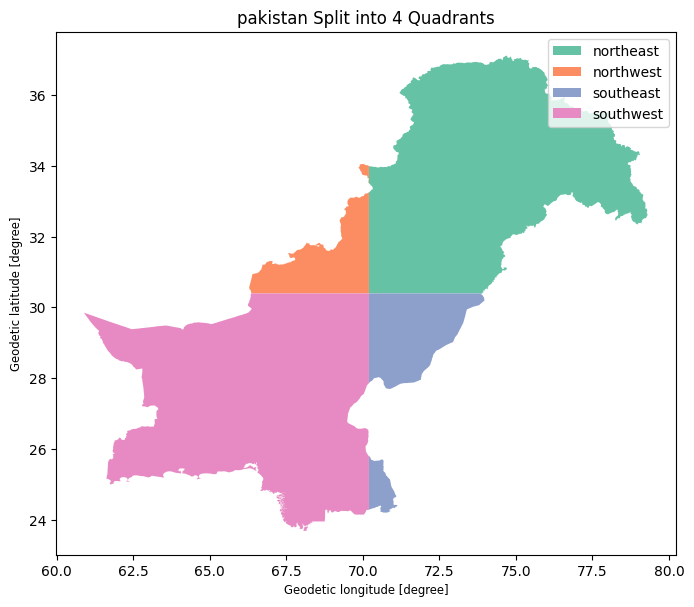

Mubarak ho! northeast_part.shp kamyabi se save ho gayi hai.
Mubarak ho! northwest_part.shp kamyabi se save ho gayi hai.
Mubarak ho! southeast_part.shp kamyabi se save ho gayi hai.
Mubarak ho! southwest_part.shp kamyabi se save ho gayi hai.


In [ ]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import GeometryCollection, LineString, Polygon
from shapely.ops import split

# ==========================================
# 1. INPUT FILE PATH (Yahan badla hai)
# ==========================================
# Humne shp_sindh ko badal kar aapke folder 'pk_shapefile' ka path de diya hai
input_path = "/content/drive/MyDrive/pk_shapefile"
gdf = gpd.read_file(input_path)

# Fix: Pure map ka exact absolute center point nikalne ke liye
centroid = gdf.unary_union.centroid

# Get bounds of the polygon
minx, miny, maxx, maxy = gdf.total_bounds

# Create vertical and horizontal lines through the centroid
vertical_line = LineString([(centroid.x, miny), (centroid.x, maxy)])
horizontal_line = LineString([(minx, centroid.y), (maxx, centroid.y)])

# Fix: Pure pakistan ke map ko vertical split kiya (bina index 0 ke error ke)
split_polys_first = split(gdf.unary_union, vertical_line)

# Fix: Geometry types handling loop jo crash nahi hone dega
final_split = []
first_parts = (
    split_polys_first.geoms
    if hasattr(split_polys_first, "geoms")
    else [split_polys_first]
)

for part in first_parts:
    result = split(part, horizontal_line)
    if hasattr(result, "geoms"):
        for geom in result.geoms:
            if isinstance(geom, Polygon):
                final_split.append(geom)
    elif isinstance(result, Polygon):
        final_split.append(result)

# Convert the result to a GeoSeries and assign to GeoDataFrame
split_gdf = gpd.GeoDataFrame(geometry=gpd.GeoSeries(final_split), crs=gdf.crs)


# Function to assign quadrant based on centroid position
def assign_quadrant(geometry, original_centroid):
    c = geometry.centroid
    if c.x >= original_centroid.x and c.y >= original_centroid.y:
        return "northeast"
    elif c.x < original_centroid.x and c.y >= original_centroid.y:
        return "northwest"
    elif c.x < original_centroid.x and c.y < original_centroid.y:
        return "southwest"
    else:
        return "southeast"


# Assign quadrant names
split_gdf["quadrant"] = split_gdf.geometry.apply(
    assign_quadrant, original_centroid=centroid
)

# Optional: Map ko screen par plot karke dekhne ke liye
split_gdf.plot(column="quadrant", legend=True, figsize=(8, 8), cmap="Set2")
plt.title("pakistan Split into 4 Quadrants")
plt.show()

# ==========================================
# 2. OUTPUT FOLDER PATH (Yahan fix kiya hai)
# ==========================================
# Colab me desktop ka path 'C:\\Users...' nahi chalta.
# Isliye output ko aapke Google Drive ke 'pk_shapefile' folder me hi save karwa rahe hain.
output_folder = "/content/drive/MyDrive/pk_shapefile"
os.makedirs(output_folder, exist_ok=True)

for quadrant, group in split_gdf.groupby("quadrant"):
    output_path = f"{output_folder}/{quadrant}_part.shp"
    group.to_file(output_path)
    print(f"Mubarak ho! {quadrant}_part.shp kamyabi se save ho gayi hai.")


/tmp/ipykernel_443/226764033.py:39: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  merged_geometry = combined_gdf.unary_union



Mubarak ho! Pakistan ka map successfully 'merge_polygon' ke naam se merge ho gaya hai. 🎉


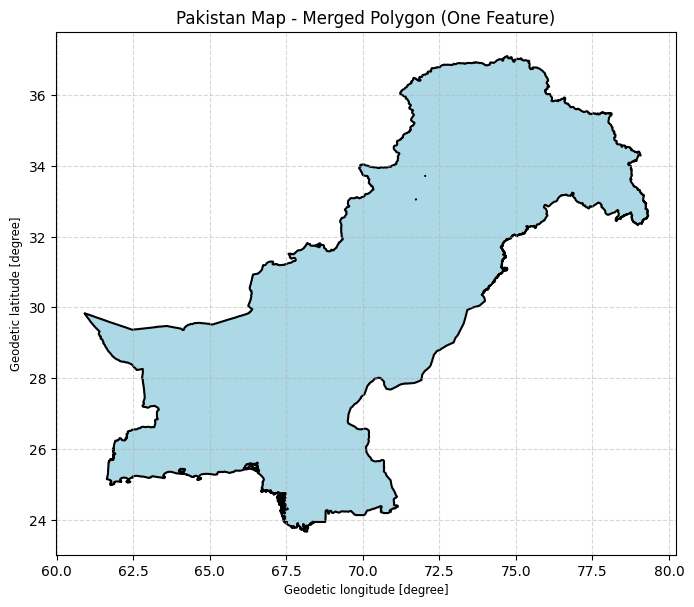


Taiyari ho rahi hai file ko aapke PC ke 'Desktop\DIP' folder ke liye download karne ki...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download start ho chuka hai! Jab zip download ho jaye, to use extract karke apne Desktop\DIP folder mein rakh lein.


In [7]:
import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files  # File ko seedha PC par download karne ke liye

# ==========================================
# STEP 1: INPUT PATH & READING DATA
# ==========================================
# Google Drive ka input folder jahan split files hain
input_folder = "/content/drive/MyDrive/pk_shapefile"
quadrants = ["northeast", "northwest", "southwest", "southeast"]

parts_list = []
original_crs = None

# Har quadrant file ko loop ke zariye read (load) karna
for quadrant in quadrants:
    file_path = f"{input_folder}/{quadrant}_part.shp"

    if os.path.exists(file_path):
        part_gdf = gpd.read_file(file_path)
        parts_list.append(part_gdf)

        # CRS (Coordinate Reference System) ko save karna taake map kharab na ho
        if original_crs is None:
            original_crs = part_gdf.crs
    else:
        print(f"Warning: {quadrant}_part.shp nahi mili. Path ya naam check karein.")

# ==========================================
# STEP 2: PROCESS & FUNCTION (MERGING POLYGONS)
# ==========================================
if len(parts_list) > 0:
    # Tamam quadrants ko aapas mein jodhna
    combined_gdf = gpd.GeoDataFrame(pd.concat(parts_list, ignore_index=True), crs=original_crs)

    # Khas function (unary_union) jo andar ki lines dissolve karke ek single polygon banata hai
    merged_geometry = combined_gdf.unary_union

    # Naya clean data table banana jis mein sirf merged boundary ho
    merged_gdf = gpd.GeoDataFrame(geometry=gpd.GeoSeries([merged_geometry]), crs=original_crs)

    # ==========================================
    # STEP 3: OUTPUT SETTING & VISUALIZATION
    # ==========================================
    # Output file ka naam jo aapne bataya: 'merge_polygon'
    output_name = "merge_polygon"

    # Pehle Colab ke temporary memory mein save karenge
    merged_gdf.to_file(f"{output_name}.shp")

    print(f"\nMubarak ho! Pakistan ka map successfully '{output_name}' ke naam se merge ho gaya hai. 🎉")

    # Map ko screen par show karna
    fig, ax = plt.subplots(figsize=(8, 8))
    merged_gdf.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=1.5)
    plt.title("Pakistan Map - Merged Polygon (One Feature)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

    # ==========================================
    # STEP 4: DOWNLOAD TO PC (Desktop\DIP Folder ke liye)
    # ==========================================
    print(f"\nTaiyari ho rahi hai file ko aapke PC ke 'Desktop\\DIP' folder ke liye download karne ki...")

    # Shapefile ki sab companion files (.shp, .shx, .dbf, .prj) ko ek zip mein pack karna
    os.system(f"zip -r {output_name}.zip {output_name}.*")

    # Yeh command aapke browser mein automatic download window open karegi
    files.download(f"{output_name}.zip")
    print("Download start ho chuka hai! Jab zip download ho jaye, to use extract karke apne Desktop\\DIP folder mein rakh lein.")

else:
    print("Error: Kisi bhi quadrant ki shapefile nahi mili! Pehle apna Google Drive wala pehla cell lazmi run karein.")


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
